# U-net

## Imports

In [ ]:
# In[4]:

import os, json, time, hashlib, shutil
from pathlib import Path
from itertools import product
import random  # NEW

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

from sklearn.metrics import confusion_matrix, classification_report

# --------------------------
# Reproducible seeding
# --------------------------
SEED = 42  # or any integer you like

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Make cuDNN deterministic (slightly slower but reproducible)
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(SEED)
print(f"Global seed set to: {SEED}")

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


## Basic Data Loading

In [ ]:
from pathlib import Path
import numpy as np

# DATASET_NAME = "ECG5000"
# DATASET_NAME = "NonInvasiveFetalECGThorax1"
DATASET_NAME = "NonInvasiveFetalECGThorax2"

# Robust path resolution (handles running notebook from different cwd)
HERE = Path().resolve()
DATA_ROOT = HERE / "Data"
if not DATA_ROOT.exists():
    # fallback: search one level up (common if notebook is in subfolder)
    if (HERE.parent / "Data").exists():
        DATA_ROOT = HERE.parent / "Data"

DATA_DIR = DATA_ROOT / DATASET_NAME
assert DATA_DIR.exists(), f"Dataset folder not found: {DATA_DIR}"

train_path = DATA_DIR / f"{DATASET_NAME}_TRAIN.ts"
test_path  = DATA_DIR / f"{DATASET_NAME}_TEST.ts"
assert train_path.exists(), f"Missing: {train_path}"
assert test_path.exists(), f"Missing: {test_path}"

print("Using dataset:", DATASET_NAME)
print("Train file:", train_path)
print("Test file :", test_path)

def load_ucr_ts(ts_path: Path):
    """
    Minimal UCR/UEA .ts loader for univariate classification datasets.
    Returns: X (N, L) float32, y_raw (N,) as original labels (strings)
    """
    X, y = [], []
    in_data = False

    with ts_path.open("r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue

            low = line.lower()

            # header control
            if low.startswith("@data"):
                in_data = True
                continue
            if not in_data:
                continue

            # data lines:
            # format typically: series_values:label
            # where series_values are comma-separated floats
            if ":" not in line:
                continue

            series_part, label_part = line.rsplit(":", 1)
            label = label_part.strip()
            series_str = series_part.strip()

            # Handle optional parentheses/whitespace
            # Values may be like "0.1,0.2,..." (univariate)
            vals = [v for v in series_str.split(",") if v != ""]
            vals = np.array(vals, dtype=np.float32)

            X.append(vals)
            y.append(label)

    X = np.stack(X, axis=0).astype(np.float32)
    y = np.array(y)

    return X, y

# Load raw labels
X_train_full, y_train_raw = load_ucr_ts(train_path)
X_test, y_test_raw        = load_ucr_ts(test_path)

# Map labels -> 0..K-1 consistently using TRAIN classes
unique_labels = sorted(np.unique(y_train_raw).tolist())
label_to_idx = {lab: i for i, lab in enumerate(unique_labels)}

y_train_full = np.array([label_to_idx[lab] for lab in y_train_raw], dtype=np.int64)
y_test       = np.array([label_to_idx.get(lab, -1) for lab in y_test_raw], dtype=np.int64)

# Sanity check: test labels must all exist in training label set
assert (y_test >= 0).all(), "Found test labels not present in training labels."

classes = unique_labels  # for plotting
num_classes = len(classes)
seq_len = X_train_full.shape[1]

print("Train shape:", X_train_full.shape, "Test shape:", X_test.shape)
print("Classes:", classes, "| num_classes:", num_classes, "| seq_len:", seq_len)


# X_train_full, y_train_full, X_test, y_test already loaded above

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full
)


Using dataset: NonInvasiveFetalECGThorax1
Train file: E:\Repos\U-net_cikk\Data\NonInvasiveFetalECGThorax1\NonInvasiveFetalECGThorax1_TRAIN.ts
Test file : E:\Repos\U-net_cikk\Data\NonInvasiveFetalECGThorax1\NonInvasiveFetalECGThorax1_TEST.ts
Train shape: (1800, 750) Test shape: (1965, 750)
Classes: ['1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '3', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '4', '40', '41', '42', '5', '6', '7', '8', '9'] | num_classes: 42 | seq_len: 750


## Normalize per sample

In [ ]:

def zscore_per_sample(X, eps=1e-8):
    mu = X.mean(axis=1, keepdims=True)
    sd = X.std(axis=1, keepdims=True)
    return (X - mu) / (sd + eps)

X_train = zscore_per_sample(X_train)
X_val   = zscore_per_sample(X_val)
X_test  = zscore_per_sample(X_test)


## Pytorch Datalset/Dataloader

In [ ]:
class ECGDataset(Dataset):
    def __init__(self, X, y, augment=False, max_shift=0):
        """
        X: np.array, shape (N, L)
        y: np.array, shape (N,)
        augment: if True, apply random time-shift
        max_shift: maximum absolute shift (in samples). 0 disables shifting.
        """
        self.X = torch.from_numpy(X).unsqueeze(1)  # (N, 1, L)
        self.y = torch.from_numpy(y).long()
        self.augment = augment
        self.max_shift = int(max_shift)

    def __len__(self):
        return len(self.X)

    def _random_shift(self, x):
        """
        x: tensor of shape (C, L)
        Returns: shifted tensor with zero-padding (no wrap-around).
        """
        if self.max_shift <= 0:
            return x

        # Sample shift uniformly in [-max_shift, max_shift]
        shift = torch.randint(-self.max_shift, self.max_shift + 1, (1,)).item()
        if shift == 0:
            return x

        L = x.shape[-1]

        if shift > 0:
            # Shift to the right: new values at the left are zero
            pad = torch.zeros_like(x[..., :shift])
            x_shifted = torch.cat([pad, x[..., :-shift]], dim=-1)
        else:
            # Shift to the left: new values at the right are zero
            s = -shift
            pad = torch.zeros_like(x[..., :s])
            x_shifted = torch.cat([x[..., s:], pad], dim=-1)

        return x_shifted

    def __getitem__(self, i):
        x = self.X[i]
        y = self.y[i]

        if self.augment and self.max_shift > 0:
            x = self._random_shift(x)

        return x, y


# ---- Augmentation settings ----
AUG_TIME_SHIFT = False   # set to True for the augmented experiment
MAX_SHIFT = 5            # in samples, e.g. ±5; tune as desired

train_ds = ECGDataset(
    X_train, y_train,
    augment=AUG_TIME_SHIFT,
    max_shift=MAX_SHIFT,
)
val_ds   = ECGDataset(
    X_val,   y_val,
    augment=False,
    max_shift=0,
)
test_ds  = ECGDataset(
    X_test,  y_test,
    augment=False,
    max_shift=0,
)

# Optional: deterministic shuffling if you have SEED defined
# g = torch.Generator()
# g.manual_seed(SEED)

train_loader = DataLoader(
    train_ds,
    batch_size=128,
    shuffle=True,
    drop_last=True,
    # generator=g,
)

val_loader = DataLoader(
    val_ds,
    batch_size=256,
    shuffle=False,
)

test_loader = DataLoader(
    test_ds,
    batch_size=256,
    shuffle=False,
)


## Train/Eval utils

In [ ]:
def train_one_epoch(model, loader, opt, criterion, epoch=0):
    model.train()
    total_loss, correct, n = 0.0, 0, 0

    pbar = tqdm(loader, desc=f"Train {epoch:02d}", leave=False)
    for xb, yb in pbar:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        opt.step()

        bs = xb.size(0)
        total_loss += loss.item() * bs
        correct += (logits.argmax(1) == yb).sum().item()
        n += bs

        pbar.set_postfix(loss=f"{total_loss/n:.4f}", acc=f"{correct/n:.3f}")

    return total_loss/n, correct/n


@torch.no_grad()
def eval_model(model, loader, criterion, epoch=0):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    all_preds, all_y = [], []

    pbar = tqdm(loader, desc=f"Eval  {epoch:02d}", leave=False)
    for xb, yb in pbar:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss = criterion(logits, yb)

        bs = xb.size(0)
        total_loss += loss.item() * bs
        preds = logits.argmax(1)

        correct += (preds == yb).sum().item()
        n += bs

        all_preds.append(preds.cpu().numpy())
        all_y.append(yb.cpu().numpy())

        pbar.set_postfix(loss=f"{total_loss/n:.4f}", acc=f"{correct/n:.3f}")

    return total_loss/n, correct/n, np.concatenate(all_y), np.concatenate(all_preds)


def fit(model, train_loader, val_loader, epochs=40, lr=1e-3, weight_decay=1e-4):
    """
    Train with validation:
    - train_loader: training data
    - val_loader:   validation data (used for model selection)
    """
    model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss()

    best_val_acc, best_state = 0.0, None
    history = []

    for ep in range(epochs):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, opt, criterion, ep)
        val_loss, val_acc, _, _ = eval_model(model, val_loader, criterion, ep)
        history.append((tr_loss, tr_acc, val_loss, val_acc))

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = {k: v.detach().cpu() for k, v in model.state_dict().items()}

        print(
            f"Epoch {ep:02d}/{epochs-1} | "
            f"train acc {tr_acc:.3f} loss {tr_loss:.4f} | "
            f"val acc {val_acc:.3f} loss {val_loss:.4f}"
        )

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, history




## Grad-CAM utils

In [ ]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

class GradCAM1D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, inp, out):
            self.activations = out.detach()

        def backward_hook(module, grad_in, grad_out):
            self.gradients = grad_out[0].detach()

        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_full_backward_hook(backward_hook)

    def __call__(self, x, class_idx=None):
        """
        x: (1, 1, L)
        returns cam: (L,)
        """
        self.model.zero_grad()
        logits = self.model(x)
        if class_idx is None:
            class_idx = logits.argmax(1).item()

        score = logits[:, class_idx]
        score.backward()

        # activations: (1, C, L') gradients: (1, C, L')
        A = self.activations
        dA = self.gradients

        # global-average pool gradients over time to get weights per channel
        weights = dA.mean(dim=-1, keepdim=True)  # (1, C, 1)

        cam = (weights * A).sum(dim=1)  # (1, L')
        cam = F.relu(cam)

        # upsample cam to input length
        cam = F.interpolate(cam.unsqueeze(1), size=x.shape[-1], mode="linear", align_corners=False)
        cam = cam.squeeze().cpu().numpy()

        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, class_idx, logits.softmax(1).detach().cpu().numpy()

def show_gradcam_1d(model, dataset, idx, class_names=None, target_layer=None):
    model.eval()
    x, y = dataset[idx]
    x_in = x.unsqueeze(0).to(device)

    # pick default layer if not provided
    if target_layer is None:
        # try to use last conv in decoder (dec1) if exists
        target_layer = getattr(model, "dec1", None)
        if target_layer is not None and hasattr(target_layer, "net"):
            # last Conv1d in that block
            target_layer = target_layer.net[3]
        else:
            # fallback: last Conv1d we can find
            convs = [m for m in model.modules() if isinstance(m, torch.nn.Conv1d)]
            target_layer = convs[-1]

    cam_engine = GradCAM1D(model, target_layer)
    cam, pred_idx, probs = cam_engine(x_in)

    sig = x.squeeze().numpy()
    L = sig.shape[0]

    plt.figure(figsize=(10,3))
    plt.plot(sig, label="ECG")
    plt.fill_between(np.arange(L), sig.min(), sig.max(), where=cam>0,
                     alpha=0.3, step="mid")
    plt.title(
        f"Grad-CAM 1D | true={y.item()} pred={pred_idx} "
        + (f"({class_names[pred_idx]})" if class_names else "")
    )
    plt.legend()
    plt.show()

    print("Class probs:", probs[0])


import torch
import torch.nn.functional as F

def match_length(a, b):
    """
    Make tensors a and b have the same last-dimension length by center-cropping the longer one.
    a, b: (N, C, L)
    Returns: (a_matched, b_matched)
    """
    La = a.shape[-1]
    Lb = b.shape[-1]
    if La == Lb:
        return a, b

    if La > Lb:
        diff = La - Lb
        left = diff // 2
        right = diff - left
        a = a[..., left:La-right]
    else:
        diff = Lb - La
        left = diff // 2
        right = diff - left
        b = b[..., left:Lb-right]

    return a, b



## Model 1: Compact 1D U-net

In [ ]:
class ConvBlock1D(nn.Module):
    def __init__(self, cin, cout, k=3, p=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(cin, cout, k, padding=p),
            nn.BatchNorm1d(cout),
            nn.ReLU(),
            nn.Conv1d(cout, cout, k, padding=p),
            nn.BatchNorm1d(cout),
            nn.ReLU(),
        )
    def forward(self, x): return self.net(x)

class UNet1DClassifier(nn.Module):
    def __init__(self, in_ch=1, base=32, num_classes=5, dropout=0.0):
        super().__init__()
        self.enc1 = ConvBlock1D(in_ch, base)
        self.down1 = nn.MaxPool1d(2)
        self.enc2 = ConvBlock1D(base, base*2)
        self.down2 = nn.MaxPool1d(2)
        self.enc3 = ConvBlock1D(base*2, base*4)

        self.up2 = nn.ConvTranspose1d(base*4, base*2, 2, stride=2)
        self.dec2 = ConvBlock1D(base*4, base*2)
        self.up1 = nn.ConvTranspose1d(base*2, base, 2, stride=2)
        self.dec1 = ConvBlock1D(base*2, base)

        # classifier head
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(base, num_classes)
        )

    def forward(self, x):
        e1 = self.enc1(x)      # (B, base, L)
        e2 = self.enc2(self.down1(e1))  # (B, 2base, L/2)
        e3 = self.enc3(self.down2(e2))  # (B, 4base, L/4)

        d2 = self.up2(e3)
        d2, e2 = match_length(d2, e2)
        d2 = torch.cat([d2, e2], dim=1)

        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1, e1 = match_length(d1, e1)
        d1 = torch.cat([d1, e1], dim=1)

        d1 = self.dec1(d1)

        return self.head(d1)

## Model 2: 1D U-net + FNO bottleneck

In [ ]:
class SpectralConv1d(nn.Module):
    """
    1D spectral conv: FFT -> keep modes -> complex linear map -> iFFT
    """
    def __init__(self, in_channels, out_channels, modes):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.modes = modes
        scale = 1 / (in_channels * out_channels)
        self.weights = nn.Parameter(scale * torch.randn(in_channels, out_channels, modes, dtype=torch.cfloat))

    def forward(self, x):
        # x: (B, C, L)
        B, C, L = x.shape
        x_ft = torch.fft.rfft(x, dim=-1)  # (B, C, L//2+1)
        out_ft = torch.zeros(B, self.out_channels, x_ft.size(-1), dtype=torch.cfloat, device=x.device)

        m = min(self.modes, x_ft.size(-1))
        out_ft[:, :, :m] = torch.einsum("bci,coi->boi", x_ft[:, :, :m], self.weights[:, :, :m])
        x = torch.fft.irfft(out_ft, n=L, dim=-1)
        return x

class FNOBlock1d(nn.Module):
    def __init__(self, width, modes):
        super().__init__()
        self.spec = SpectralConv1d(width, width, modes)
        self.pw = nn.Conv1d(width, width, 1)
        self.bn = nn.BatchNorm1d(width)
    def forward(self, x):
        x = self.spec(x) + self.pw(x)
        return F.relu(self.bn(x))

class UNetFNO1DClassifier(nn.Module):
    def __init__(self, in_ch=1, base=32, num_classes=5, modes=16, fno_layers=2, dropout=0.0):
        super().__init__()
        self.enc1 = ConvBlock1D(in_ch, base)
        self.down1 = nn.MaxPool1d(2)
        self.enc2 = ConvBlock1D(base, base*2)
        self.down2 = nn.MaxPool1d(2)
        self.enc3 = ConvBlock1D(base*2, base*4)

        self.fno = nn.Sequential(*[FNOBlock1d(base*4, modes) for _ in range(fno_layers)])

        self.up2 = nn.ConvTranspose1d(base*4, base*2, 2, stride=2)
        self.dec2 = ConvBlock1D(base*4, base*2)
        self.up1 = nn.ConvTranspose1d(base*2, base, 2, stride=2)
        self.dec1 = ConvBlock1D(base*2, base)

        self.head = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(base, num_classes)
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.down1(e1))
        e3 = self.enc3(self.down2(e2))

        b = self.fno(e3)

        d2 = self.up2(b)
        d2, e2 = match_length(d2, e2)
        d2 = torch.cat([d2, e2], dim=1)

        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1, e1 = match_length(d1, e1)
        d1 = torch.cat([d1, e1], dim=1)

        d1 = self.dec1(d1)

        return self.head(d1)


# Attention U-net

## Model 1: Attention U-net (Attention gate + Attention up block)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class AttentionGate1D(nn.Module):
    """
    Attention gate for 1D skip connections.
    g: gating signal from decoder (coarser)
    x: skip features from encoder (finer)
    returns: attended skip features
    """
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv1d(F_g, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm1d(F_int)
        )
        self.W_x = nn.Sequential(
            nn.Conv1d(F_l, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm1d(F_int)
        )
        self.psi = nn.Sequential(
            nn.Conv1d(F_int, 1, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm1d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        # g and x should have same temporal length here
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)  # (B,1,L)
        return x * psi       # broadcast channel-wise


class UpBlockAtt1D(nn.Module):
    """
    Upsample, apply attention gate on skip, concat, then ConvBlock1D.
    """
    def __init__(self, F_g, F_l, F_out):
        super().__init__()
        self.up = nn.ConvTranspose1d(F_g, F_out, kernel_size=2, stride=2)
        self.att = AttentionGate1D(F_g=F_out, F_l=F_l, F_int=F_out//2)
        self.conv = ConvBlock1D(F_out + F_l, F_out)

    def forward(self, g, x_skip):
        g_up = self.up(g)
        # in case of odd lengths, align by trimming/padding
        if g_up.size(-1) != x_skip.size(-1):
            minL = min(g_up.size(-1), x_skip.size(-1))
            g_up = g_up[..., :minL]
            x_skip = x_skip[..., :minL]

        x_att = self.att(g_up, x_skip)
        x = torch.cat([g_up, x_att], dim=1)
        return self.conv(x)


In [ ]:
class AttUNet1DClassifier(nn.Module):
    """
    1D Attention U-Net used as feature extractor for classification.
    Attention gates are applied on skip connections.
    """
    def __init__(self, in_ch=1, base=32, num_classes=5, dropout=0.0):
        super().__init__()
        # Encoder
        self.enc1 = ConvBlock1D(in_ch, base)
        self.down1 = nn.MaxPool1d(2)
        self.enc2 = ConvBlock1D(base, base*2)
        self.down2 = nn.MaxPool1d(2)
        self.enc3 = ConvBlock1D(base*2, base*4)

        # Decoder with attention on skips
        self.up2 = UpBlockAtt1D(F_g=base*4, F_l=base*2, F_out=base*2)
        self.up1 = UpBlockAtt1D(F_g=base*2, F_l=base,   F_out=base)

        # Classification head
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(base, num_classes)
        )

    def forward(self, x):
        e1 = self.enc1(x)              # (B, base, L)
        e2 = self.enc2(self.down1(e1)) # (B, 2base, L/2)
        e3 = self.enc3(self.down2(e2)) # (B, 4base, L/4)

        d2 = self.up2(e3, e2)          # (B, 2base, L/2)
        d1 = self.up1(d2, e1)          # (B, base, L)

        return self.head(d1)


## Model 2: Attention U-net + FNO

In [ ]:
class AttUNetFNO1DClassifier(nn.Module):
    """
    1D Attention U-Net with FNO bottleneck for classification.
    """
    def __init__(self, in_ch=1, base=32, num_classes=5,
                 modes=16, fno_layers=2, dropout=0.0):
        super().__init__()
        # Encoder
        self.enc1 = ConvBlock1D(in_ch, base)
        self.down1 = nn.MaxPool1d(2)
        self.enc2 = ConvBlock1D(base, base*2)
        self.down2 = nn.MaxPool1d(2)
        self.enc3 = ConvBlock1D(base*2, base*4)

        # FNO bottleneck (reuse your FNOBlock1d)
        self.fno = nn.Sequential(*[
            FNOBlock1d(base*4, modes) for _ in range(fno_layers)
        ])

        # Decoder with attention skips
        self.up2 = UpBlockAtt1D(F_g=base*4, F_l=base*2, F_out=base*2)
        self.up1 = UpBlockAtt1D(F_g=base*2, F_l=base,   F_out=base)

        # Classification head
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(base, num_classes)
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.down1(e1))
        e3 = self.enc3(self.down2(e2))

        b = self.fno(e3)

        d2 = self.up2(b, e2)
        d1 = self.up1(d2, e1)

        return self.head(d1)


# ResNet1D for baseline

In [ ]:

class BasicBlock1D(nn.Module):
    """
    Basic ResNet block for 1D signals:
    Conv1d -> BN -> ReLU -> Conv1d -> BN + skip
    """
    expansion = 1

    def __init__(self, in_planes, planes, stride=1, downsample=None):
        super().__init__()
        self.conv1 = nn.Conv1d(in_planes, planes, kernel_size=3,
                               stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm1d(planes)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv1d(planes, planes, kernel_size=3,
                               stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm1d(planes)
        self.downsample = downsample

    def forward(self, x):
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        if self.downsample is not None:
            identity = self.downsample(x)

        out += identity
        out = self.relu(out)
        return out


class ResNet1DClassifier(nn.Module):
    """
    1D ResNet baseline for ECG classification.
    Roughly analogous to ResNet-18 in 1D.

    base: controls the width of the network (like your U-Net base channels).
    """
    def __init__(self, in_ch=1, base=32, num_classes=5, dropout=0.0):
        super().__init__()

        self.in_planes = base

        # Initial conv: keep it simple and similar scale to U-Net
        self.conv1 = nn.Conv1d(in_ch, base, kernel_size=7,
                               stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm1d(base)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool1d(kernel_size=3, stride=2, padding=1)

        # ResNet-18 style layer sizes: [base, 2*base, 4*base, 8*base]
        self.layer1 = self._make_layer(BasicBlock1D,  base,      blocks=2, stride=1)
        self.layer2 = self._make_layer(BasicBlock1D,  base * 2,  blocks=2, stride=2)
        self.layer3 = self._make_layer(BasicBlock1D,  base * 4,  blocks=2, stride=2)
        self.layer4 = self._make_layer(BasicBlock1D,  base * 8,  blocks=2, stride=2)

        self.avgpool = nn.AdaptiveAvgPool1d(1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(base * 8, num_classes)

    def _make_layer(self, block, planes, blocks, stride=1):
        downsample = None
        if stride != 1 or self.in_planes != planes * block.expansion:
            downsample = nn.Sequential(
                nn.Conv1d(self.in_planes, planes * block.expansion,
                          kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm1d(planes * block.expansion),
            )

        layers = []
        layers.append(block(self.in_planes, planes, stride, downsample))
        self.in_planes = planes * block.expansion
        for _ in range(1, blocks):
            layers.append(block(self.in_planes, planes))

        return nn.Sequential(*layers)

    def forward(self, x):
        # x: (B, 1, L)
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.avgpool(x)      # (B, C, 1)
        x = torch.flatten(x, 1)  # (B, C)
        x = self.dropout(x)
        x = self.fc(x)
        return x


# Hyperparameter tuning

Shared:

- base (channels): 16, 32, 48, 64
- lr: 1e-3, 5e-4, 3e-4
- weight_decay: 0, 1e-5, 1e-4, 5e-4
- epochs: fixed (30–60); not a search target unless you want early stopping

Base U-Net-specific:

- dropout: 0.0, 0.1, 0.2, 0.3 (we’ll add it optionally)
- kernel_size: 3 or 5 (optional; more invasive)

FNO-specific:

- modes: 8, 12, 16, 24, 32
- fno_layers: 1, 2, 3

## Evaluation prep

In [ ]:
def plot_confusion(cm, class_names, normalize=False, title="Confusion"):
    if normalize:
        cm = cm.astype(float) / (cm.sum(axis=1, keepdims=True) + 1e-12)

    fig, ax = plt.subplots(figsize=(6,5))
    im = ax.imshow(cm, interpolation="nearest")
    ax.figure.colorbar(im, ax=ax)

    ax.set(
        xticks=np.arange(len(class_names)),
        yticks=np.arange(len(class_names)),
        xticklabels=class_names,
        yticklabels=class_names,
        xlabel="Predicted",
        ylabel="True",
        title=title
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

    fmt = ".2f" if normalize else "d"
    thresh = cm.max() * 0.6
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i,j], fmt),
                    ha="center", va="center",
                    color="white" if cm[i,j] > thresh else "black")
    plt.show()


def eval_and_plot(model, loader, name="Model"):
    crit = nn.CrossEntropyLoss()
    _, acc, y_true, y_pred = eval_model(model, loader, crit)
    print(f"{name} acc: {acc:.4f}\n")
    print(classification_report(y_true, y_pred, digits=4))

    cm = confusion_matrix(y_true, y_pred)
    plot_confusion(cm, [str(c) for c in classes], False, f"{name} Confusion (counts)")
    plot_confusion(cm, [str(c) for c in classes], True,  f"{name} Confusion (norm)")

    return acc


## Grid Search

In [ ]:
# ===========================================================
# Resumable Gridsearch (backend) — GLOBAL QUEUE RESUME
#   - Completed detection via filesystem scan (not leaderboard)
#   - Regime included in config_key (no collisions)
#   - Saves to: models/<DATASET>/<family>/<regime>/run_xxx/
# ===========================================================

import hashlib, json, time
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# ---- Grid definitions ----
grid_shared = {
    "base": [16, 32, 48],
    "lr": [1e-3, 5e-4],
    "weight_decay": [0.0, 1e-4],
    "dropout": [0.0, 0.1, 0.2],
}
grid_fno = {
    "modes": [8, 16, 24],
    "fno_layers": [1, 2],
}

# ---- Regimes to run ----
# You can add "e80", "e200", etc. safely.
REGIMES = ["e40", "e120", "plateau"]

# Plateau stopping definition (used only when train_regime == "plateau")
PLATEAU_CFG = dict(
    min_epochs=40,         # don’t stop before this
    max_epochs=300,        # hard cap
    patience=20,           # how many epochs without improvement before stopping
    min_delta_acc=1e-4,    # required improvement in val_acc to reset patience
    min_delta_loss=1e-4,   # required improvement in val_loss to reset patience
)

# ---- Model directories ----
MODELS_DIR = Path("models") / DATASET_NAME
MODELS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_DIRS = {
    "base_unet":    MODELS_DIR / "base_unet",
    "unet_fno":     MODELS_DIR / "unet_fno",
    "att_unet":     MODELS_DIR / "att_unet",
    "att_unet_fno": MODELS_DIR / "att_unet_fno",
    "resnet1d":     MODELS_DIR / "resnet1d",
}
for d in MODEL_DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

LEADERBOARD_PATH = MODELS_DIR / "leaderboard.csv"  # still used for logging only


# ---- Helpers ----
def expand_grid(g):
    keys, vals = list(g.keys()), list(g.values())
    return [dict(zip(keys, v)) for v in product(*vals)]


def normalize_cfg(cfg: dict) -> dict:
    """
    Ensure regime is always present and types are JSON-stable.
    """
    c = dict(cfg)
    if "train_regime" not in c:
        raise ValueError("cfg is missing 'train_regime' (required).")
    # Make sure numeric values are stable
    for k, v in list(c.items()):
        if isinstance(v, np.generic):
            c[k] = v.item()
    return c


def make_config_key(model_type: str, cfg: dict) -> str:
    """
    Hash includes ALL cfg fields (including train_regime).
    This is the single identity of a job.
    """
    cfg = normalize_cfg(cfg)
    items = sorted(cfg.items())
    s = model_type + "|" + "|".join([f"{k}={v}" for k, v in items])
    return hashlib.md5(s.encode("utf-8")).hexdigest()


def iter_run_dirs_filesystem():
    """
    Yield (model_type, train_regime, run_dir) for:
      models/<DATASET>/<model_type>/<train_regime>/run_XXX/
    """
    for model_type, base_dir in MODEL_DIRS.items():
        if not base_dir.exists():
            continue
        for regime_dir in sorted([p for p in base_dir.iterdir() if p.is_dir()]):
            train_regime = regime_dir.name
            for run_dir in sorted([p for p in regime_dir.glob("run_*") if p.is_dir()]):
                yield model_type, train_regime, run_dir


def load_completed_keys_filesystem() -> set:
    """
    Robust resume: scan folders, read config.json, compute keys.
    Does not rely on leaderboard.csv parsing.
    """
    done = set()
    for model_type, train_regime, run_dir in iter_run_dirs_filesystem():
        cfg_path = run_dir / "config.json"
        if not cfg_path.exists():
            continue
        try:
            cfg = json.loads(cfg_path.read_text())
            # force regime from folder if missing/mismatched
            cfg["train_regime"] = cfg.get("train_regime", train_regime)
            done.add(make_config_key(model_type, cfg))
        except Exception:
            continue
    return done


def next_run_dir(model_type: str, train_regime: str):
    parent = MODEL_DIRS[model_type] / str(train_regime)
    parent.mkdir(parents=True, exist_ok=True)

    runs = sorted([p for p in parent.glob("run_*") if p.is_dir()])
    rid = len(runs) + 1
    rd = parent / f"run_{rid:03d}"
    rd.mkdir(exist_ok=False)
    return rd, rid


def save_run(model, model_type, cfg, metrics):
    cfg = normalize_cfg(cfg)
    train_regime = cfg["train_regime"]

    rd, rid = next_run_dir(model_type, train_regime)

    torch.save(model.state_dict(), rd / "model.pt")
    (rd / "config.json").write_text(json.dumps(cfg, indent=2))
    (rd / "metrics.json").write_text(json.dumps(metrics, indent=2))

    row = {
        "timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
        "model_type": model_type,
        "train_regime": train_regime,
        "run_id": rid,
        "run_dir": str(rd.as_posix()),
        "config_key": make_config_key(model_type, cfg),
        **cfg,
        **metrics,
    }

    df = pd.DataFrame([row])
    if LEADERBOARD_PATH.exists():
        df.to_csv(LEADERBOARD_PATH, mode="a", header=False, index=False)
    else:
        df.to_csv(LEADERBOARD_PATH, index=False)


# ---- Build model from config ----
def build_model(model_type, cfg):
    if model_type == "base_unet":
        return UNet1DClassifier(1, cfg["base"], num_classes, cfg["dropout"])
    if model_type == "unet_fno":
        return UNetFNO1DClassifier(
            1, cfg["base"], num_classes,
            cfg["modes"], cfg["fno_layers"], cfg["dropout"]
        )
    if model_type == "att_unet":
        return AttUNet1DClassifier(1, cfg["base"], num_classes, cfg["dropout"])
    if model_type == "att_unet_fno":
        return AttUNetFNO1DClassifier(
            1, cfg["base"], num_classes,
            cfg["modes"], cfg["fno_layers"], cfg["dropout"]
        )
    if model_type == "resnet1d":
        return ResNet1DClassifier(
            in_ch=1, base=cfg["base"], num_classes=num_classes, dropout=cfg["dropout"]
        )
    raise ValueError(model_type)


def regime_to_epochs(train_regime: str):
    """
    e40 -> 40, e120 -> 120, etc.
    plateau -> None (use early stopping)
    """
    train_regime = str(train_regime).strip().lower()
    if train_regime.startswith("e") and train_regime[1:].isdigit():
        return int(train_regime[1:])
    if train_regime == "plateau":
        return None
    raise ValueError(f"Unknown train_regime: {train_regime}")


def fit_plateau(model, lr, weight_decay):
    """
    Plateau definition:
      Stop when BOTH val_acc and val_loss fail to improve
      beyond min_delta for `patience` epochs (after min_epochs),
      while always keeping the best checkpoint (best val_acc, tie-break val_loss).
    """
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    best_state = None
    best_val_acc = -1.0
    best_val_loss = float("inf")
    best_epoch = -1

    since_improve = 0
    start = time.time()

    for epoch in range(1, PLATEAU_CFG["max_epochs"] + 1):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = crit(logits, yb)
            loss.backward()
            opt.step()

        # validate
        val_loss, val_acc, _, _ = eval_model(model, val_loader, crit)

        improved_acc = (val_acc > best_val_acc + PLATEAU_CFG["min_delta_acc"])
        improved_loss = (val_loss < best_val_loss - PLATEAU_CFG["min_delta_loss"])

        # checkpoint rule: prioritize val_acc, tie-break by val_loss
        if improved_acc or (abs(val_acc - best_val_acc) <= PLATEAU_CFG["min_delta_acc"] and improved_loss):
            best_val_acc = float(val_acc)
            best_val_loss = float(val_loss)
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            since_improve = 0
        else:
            since_improve += 1

        # stop only after min_epochs
        if epoch >= PLATEAU_CFG["min_epochs"] and since_improve >= PLATEAU_CFG["patience"]:
            break

    # restore best
    if best_state is not None:
        model.load_state_dict(best_state)

    return model, {
        "epochs_ran": epoch,
        "best_epoch": best_epoch,
        "best_val_acc": best_val_acc,
        "best_val_loss": best_val_loss,
        "train_time_sec": float(time.time() - start),
    }


def run_one(model_type, cfg):
    """
    Runs exactly one job (model_type + cfg incl. train_regime).
    Saves best checkpoint (val-selected) into run folder.
    """
    cfg = normalize_cfg(cfg)
    model = build_model(model_type, cfg).to(device)

    # Train
    epochs = regime_to_epochs(cfg["train_regime"])
    if epochs is None:
        model, extra = fit_plateau(model, lr=cfg["lr"], weight_decay=cfg["weight_decay"])
        epochs_ran = int(extra["epochs_ran"])
    else:
        model, _ = fit(
            model,
            train_loader,
            val_loader,
            epochs=epochs,
            lr=cfg["lr"],
            weight_decay=cfg["weight_decay"],
        )
        extra = {"epochs_ran": int(epochs)}
        epochs_ran = int(epochs)

    # Eval metrics
    crit = nn.CrossEntropyLoss()
    val_loss, val_acc, _, _ = eval_model(model, val_loader, crit)
    test_loss, test_acc, _, _ = eval_model(model, test_loader, crit)

    metrics = {
        "val_acc": float(val_acc),
        "val_loss": float(val_loss),
        "test_acc": float(test_acc),
        "test_loss": float(test_loss),
        "epochs_ran": epochs_ran,
        "params_million": sum(p.numel() for p in model.parameters()) / 1e6,
        **extra,
    }

    save_run(model, model_type, cfg, metrics)
    return metrics


# ---- Config generation per model type ----
def get_cfgs_for_type(model_type):
    shared = expand_grid(grid_shared)
    if model_type in ["base_unet", "att_unet", "resnet1d"]:
        return shared
    else:
        fno = expand_grid(grid_fno)
        cfgs = []
        for s in shared:
            for f in fno:
                c = dict(s); c.update(f); cfgs.append(c)
        return cfgs


def build_global_job_queue(model_types, regimes):
    """
    Deterministic global order:
      for mt in model_types:
        for regime in regimes:
          for cfg in cfgs_for_type(mt):
             yield job_cfg
    """
    jobs = []
    for mt in model_types:
        cfgs = get_cfgs_for_type(mt)
        for reg in regimes:
            for cfg in cfgs:
                c = dict(cfg)
                c["train_regime"] = reg
                jobs.append((mt, c))
    return jobs


In [ ]:
# ===========================================================
# Grid search runner — GLOBAL QUEUE RESUME + ETA
#   Runs the first pending job onward (no family rotation)
# ===========================================================

import time

try:
    import ipywidgets as widgets
    from IPython.display import display
    HAVE_WIDGETS = True
except Exception:
    HAVE_WIDGETS = False


def fmt_seconds(sec):
    sec = int(max(sec, 0))
    h = sec // 3600
    m = (sec % 3600) // 60
    s = sec % 60
    if h > 0: return f"{h}h {m}m {s}s"
    if m > 0: return f"{m}m {s}s"
    return f"{s}s"


def make_overall_progress(total_remaining):
    if not HAVE_WIDGETS:
        # fallback
        def update(n_done, text=""):
            if text:
                print(f"[{n_done}/{total_remaining}] {text}")
            else:
                print(f"[{n_done}/{total_remaining}]")
        return update

    bar = widgets.IntProgress(
        value=0, min=0, max=total_remaining,
        description="Gridsearch:",
        bar_style="",
        orientation="horizontal",
        layout=widgets.Layout(width="85%")
    )
    label = widgets.HTML(value=f"<b>0 / {total_remaining}</b> completed")
    sublabel = widgets.HTML(value="Waiting to start…")
    box = widgets.VBox([bar, label, sublabel])
    display(box)

    def update(n_done, text=""):
        bar.value = n_done
        label.value = f"<b>{n_done} / {total_remaining}</b> completed"
        if text:
            sublabel.value = text

    return update


def run_global_queue_with_eta():
    base_order = ["base_unet", "unet_fno", "att_unet", "att_unet_fno", "resnet1d"]
    regimes = list(REGIMES)

    # Build all possible jobs in deterministic order
    all_jobs = build_global_job_queue(base_order, regimes)

    # Completed via filesystem (robust)
    done_keys = load_completed_keys_filesystem()

    # Pending jobs are those not in done
    pending = []
    for mt, cfg in all_jobs:
        key = make_config_key(mt, cfg)
        if key not in done_keys:
            pending.append((mt, cfg))

    total_to_run = len(pending)
    print("Total pending jobs:", total_to_run)

    if total_to_run == 0:
        print("Nothing left to run — all jobs are completed.")
        if LEADERBOARD_PATH.exists():
            df = pd.read_csv(LEADERBOARD_PATH, engine="python", on_bad_lines="skip")
            display(df.sort_values("test_acc", ascending=False).head(10))
        return

    update = make_overall_progress(total_to_run)

    done = 0
    start_time = time.time()

    for (mt, cfg) in pending:
        done += 1

        # ETA before run (based on avg so far)
        elapsed = time.time() - start_time
        avg = elapsed / max(done - 1, 1)  # use completed runs only
        remaining = total_to_run - (done - 1)
        eta_sec = remaining * avg

        update(
            done - 1,
            (
                f"<i>Next:</i> <b>{mt}</b> | regime=<b>{cfg['train_regime']}</b><br>"
                f"Elapsed: <b>{fmt_seconds(elapsed)}</b> | "
                f"Avg/run: <b>{fmt_seconds(avg)}</b> | "
                f"ETA: <b>{fmt_seconds(eta_sec)}</b>"
            )
        )

        print(f"\n[{done}/{total_to_run}] RUN {mt} regime={cfg['train_regime']} cfg={{{', '.join([f'{k}={cfg[k]}' for k in cfg if k!='train_regime'])}}}")
        met = run_one(mt, cfg)
        print("=>", met)

        # Update after run
        elapsed = time.time() - start_time
        avg = elapsed / done
        remaining = total_to_run - done
        eta_sec = remaining * avg
        update(
            done,
            (
                f"<i>Running…</i><br>"
                f"Elapsed: <b>{fmt_seconds(elapsed)}</b> | "
                f"Avg/run: <b>{fmt_seconds(avg)}</b> | "
                f"ETA: <b>{fmt_seconds(eta_sec)}</b>"
            )
        )

    elapsed_total = time.time() - start_time
    update(
        total_to_run,
        f"<b>All runs complete ✅</b><br>Total time: <b>{fmt_seconds(elapsed_total)}</b>"
    )

    # Optional summary
    if LEADERBOARD_PATH.exists():
        df = pd.read_csv(LEADERBOARD_PATH, engine="python", on_bad_lines="skip")
        display(df.sort_values("test_acc", ascending=False).head(10))


# Call this in the notebook to run/resume:
run_global_queue_with_eta()


Total pending jobs: 146



[1/146] RUN att_unet_fno regime=plateau cfg={base=48, lr=0.001, weight_decay=0.0001, dropout=0.2, modes=24, fno_layers=1}


Eval  00:   0%|          | 0/2 [00:00<?, ?it/s]

Eval  00:   0%|          | 0/2 [00:00<?, ?it/s]

Eval  00:   0%|          | 0/2 [00:00<?, ?it/s]

...

Eval  00:   0%|          | 0/2 [00:00<?, ?it/s]

Eval  00:   0%|          | 0/2 [00:00<?, ?it/s]

Eval  00:   0%|          | 0/8 [00:00<?, ?it/s]

=> {'val_acc': 0.9388888888888889, 'val_loss': 0.2295063681072659, 'test_acc': 0.9450381679389313, 'test_loss': 0.17766680973025073, 'epochs_ran': 57, 'params_million': 2.18025, 'best_epoch': 37, 'best_val_acc': 0.9388888888888889, 'best_val_loss': 0.2295063681072659, 'train_time_sec': 28.160362720489502}


,timestamp,model_type,train_regime,run_id,run_dir,config_key,base,lr,weight_decay,dropout,val_acc,val_loss,test_acc,test_loss,epochs_ran,params_million
178,2026-01-20 07:48:42,resnet1d,e40,35,models/NonInvasiveFetalECGThorax1/resnet1d/e40...,f79d7e37ed7559ea1847da15f3d42e6c,48,0.0005,0.0001,0.1,0.938889,0.229201,0.950127,0.160367,40,2.180250
162,2026-01-20 07:43:27,resnet1d,e40,19,models/NonInvasiveFetalECGThorax1/resnet1d/e40...,17f7ec11cee52e034392facfc63ce2b7,32,0.0005,0.0000,0.0,0.950000,0.219104,0.948092,0.177031,40,0.974282
193,2026-01-20 07:57:18,resnet1d,e120,14,models/NonInvasiveFetalECGThorax1/resnet1d/e12...,59481caeb360fe20999996d388cb73a9,32,0.0010,0.0000,0.1,0.925000,0.278887,0.946565,0.177504,120,0.974282
214,2026-01-20 08:16:58,resnet1d,e120,35,models/NonInvasiveFetalECGThorax1/resnet1d/e12...,1e829e91ad86734e621dd3f578832c39,48,0.0005,0.0001,0.1,0.938889,0.245659,0.945038,0.180106,120,2.180250
165,2026-01-20 07:44:15,resnet1d,e40,22,models/NonInvasiveFetalECGThorax1/resnet1d/e40...,fc14a51232be3c710a9d3f9071934662,32,0.0005,0.0001,0.0,0.941667,0.229725,0.943511,0.190605,40,0.974282
196,2026-01-20 07:59:40,resnet1d,e120,17,models/NonInvasiveFetalECGThorax1/resnet1d/e12...,795ec12346ea8f1e6aeadeb27ab63d50,32,0.0010,0.0001,0.1,0.936111,0.261641,0.943003,0.186821,120,0.974282
210,2026-01-20 08:12:42,resnet1d,e120,31,models/NonInvasiveFetalECGThorax1/resnet1d/e12...,d4cb1ddda06ae4b214db3eca1dd2010b,48,0.0005,0.0000,0.0,0.941667,0.251175,0.942494,0.200123,120,2.180250
163,2026-01-20 07:43:43,resnet1d,e40,20,models/NonInvasiveFetalECGThorax1/resnet1d/e40...,d0797c685b77c4563cc3991518e9a841,32,0.0005,0.0000,0.1,0.947222,0.240640,0.942494,0.184470,40,0.974282
212,2026-01-20 08:14:50,resnet1d,e120,33,models/NonInvasiveFetalECGThorax1/resnet1d/e12...,0f3033ece3fd98424a327b10b24e8f66,48,0.0005,0.0000,0.2,0.933333,0.237070,0.942494,0.184126,120,2.180250
211,2026-01-20 08:13:46,resnet1d,e120,32,models/NonInvasiveFetalECGThorax1/resnet1d/e12...,50a9eabc0d21749f58793c1a1ac6d5e5,48,0.0005,0.0000,0.1,0.950000,0.232432,0.942494,0.176119,120,2.180250


## Results (so far)

### Stats for the runs

In [ ]:
# ===========================================================
# Evaluate ALL trained models by scanning filesystem (robust)
#   Writes:
#     - models/<DATASET_NAME>/eval_stats_all.csv
#     - models/<DATASET_NAME>/eval_best_per_family_per_regime.csv
# ===========================================================

import json
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import f1_score, balanced_accuracy_score
import tqdm.auto as tq

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODELS_DIR = Path("models") / DATASET_NAME
EVAL_ALL_PATH  = MODELS_DIR / "eval_stats_all.csv"
EVAL_BEST_PATH = MODELS_DIR / "eval_best_per_family_per_regime.csv"

# Optional: restrict to known families (recommended). If you add more families later, extend this list.
KNOWN_FAMILIES = {"base_unet", "unet_fno", "att_unet", "att_unet_fno", "resnet1d"}


@torch.no_grad()
def eval_single_model_for_stats(model, test_loader, device=device):
    model.eval()
    y_true_all, y_pred_all = [], []
    for xb, yb in test_loader:
        xb, yb = xb.to(device), yb.to(device)
        preds = model(xb).argmax(1)
        y_true_all.append(yb.cpu().numpy())
        y_pred_all.append(preds.cpu().numpy())

    y_true = np.concatenate(y_true_all)
    y_pred = np.concatenate(y_pred_all)

    label_ids = np.arange(num_classes)

    acc = float((y_true == y_pred).mean())
    macro_f1 = float(f1_score(y_true, y_pred, labels=label_ids, average="macro", zero_division=0))
    bal_acc = float(balanced_accuracy_score(y_true, y_pred))
    return acc, macro_f1, bal_acc


def iter_run_dirs(models_dir: Path):
    """
    Yields tuples: (family, regime, run_dir)
    for run_dir matching:
      models/<dataset>/<family>/<regime>/run_XXX
    """
    if not models_dir.exists():
        return

    for family_dir in sorted([p for p in models_dir.iterdir() if p.is_dir()]):
        family = family_dir.name.strip()
        if KNOWN_FAMILIES and family not in KNOWN_FAMILIES:
            continue

        # regime dirs inside each family
        for regime_dir in sorted([p for p in family_dir.iterdir() if p.is_dir()]):
            regime = regime_dir.name.strip()

            # runs inside each regime
            for run_dir in sorted([p for p in regime_dir.glob("run_*") if p.is_dir()]):
                yield family, regime, run_dir


def evaluate_all_models_stats_filesystem():
    run_items = list(iter_run_dirs(MODELS_DIR))
    print("Scanning:", MODELS_DIR.resolve())
    print("Found run folders:", len(run_items))

    if len(run_items) == 0:
        raise RuntimeError(
            f"No runs found under {MODELS_DIR}. Expected models/<dataset>/<family>/<regime>/run_XXX/"
        )

    rows = []
    pbar = tq.tqdm(total=len(run_items), desc=f"Evaluating runs ({DATASET_NAME})")

    for family, regime, run_dir in run_items:
        cfg_path = run_dir / "config.json"
        weights_path = run_dir / "model.pt"
        metrics_path = run_dir / "metrics.json"

        if not (cfg_path.exists() and weights_path.exists()):
            pbar.update(1)
            continue

        # Load config
        with open(cfg_path, "r") as f:
            cfg = json.load(f)

        # Prefer config regime, but directory regime is authoritative
        cfg["train_regime"] = cfg.get("train_regime", regime)

        # Build + load model
        model = build_model(family, cfg)
        state = torch.load(weights_path, map_location=device)
        model.load_state_dict(state)
        model.to(device)

        # Evaluate
        acc, macro_f1, bal_acc = eval_single_model_for_stats(model, test_loader, device)

        out = {
            "family": family,
            "train_regime": str(regime),
            "run_dir": str(run_dir.as_posix()),
            "run_id": run_dir.name,  # run_XXX
            **cfg,
            "test_acc": acc,
            "macro_f1": macro_f1,
            "balanced_acc": bal_acc,
        }

        # Attach saved metrics if present (helps tables/plots)
        if metrics_path.exists():
            try:
                with open(metrics_path, "r") as f:
                    saved = json.load(f)
                for k in ["params_million", "val_acc", "best_epoch", "epochs_ran", "best_val_acc", "best_val_loss", "test_loss"]:
                    if k in saved:
                        out[k] = saved[k]
            except Exception:
                pass

        rows.append(out)
        pbar.update(1)

    pbar.close()

    df_all = pd.DataFrame(rows)
    df_all.to_csv(EVAL_ALL_PATH, index=False)
    print("Saved:", EVAL_ALL_PATH)

    # Best per family per regime (your requirement)
    df_best = (
        df_all.sort_values("macro_f1", ascending=False)
              .groupby(["train_regime", "family"], as_index=False)
              .head(1)
              .reset_index(drop=True)
    )
    df_best.to_csv(EVAL_BEST_PATH, index=False)
    print("Saved:", EVAL_BEST_PATH)

    print("Families present:", sorted(df_all["family"].unique().tolist()))
    print("Regimes present:", sorted(df_all["train_regime"].unique().tolist()))

    return df_all, df_best


df_eval_all, df_best_per_regime = evaluate_all_models_stats_filesystem()
df_best_per_regime


Scanning: E:\Repos\U-net_cikk\models\NonInvasiveFetalECGThorax1
Found run folders: 1620


Evaluating runs (NonInvasiveFetalECGThorax1):   0%|          | 0/1620 [00:00<?, ?it/s]

C:\Users\Hontika\AppData\Local\Temp\ipykernel_58464\538461237.py:101: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state = torch.load(weights_path, map_location=device)
C:\

Saved: models\NonInvasiveFetalECGThorax1\eval_stats_all.csv
Saved: models\NonInvasiveFetalECGThorax1\eval_best_per_family_per_regime.csv
Families present: ['att_unet', 'att_unet_fno', 'base_unet', 'resnet1d', 'unet_fno']
Regimes present: ['e120', 'e40', 'plateau']


,family,train_regime,run_dir,run_id,base,lr,weight_decay,dropout,test_acc,macro_f1,balanced_acc,params_million,val_acc,epochs_ran,test_loss,best_epoch,best_val_acc,best_val_loss,modes,fno_layers
0,att_unet_fno,e120,models/NonInvasiveFetalECGThorax1/att_unet_fno...,run_198,48,0.0005,0.0000,0.2,0.951654,0.949749,0.949799,2.225640,0.947222,120,0.178586,NaN,NaN,NaN,24.0,2.0
1,resnet1d,e40,models/NonInvasiveFetalECGThorax1/resnet1d/e40...,run_035,48,0.0005,0.0001,0.1,0.950127,0.947138,0.948294,2.180250,0.938889,40,0.160367,NaN,NaN,NaN,NaN,NaN
2,att_unet_fno,plateau,models/NonInvasiveFetalECGThorax1/att_unet_fno...,run_210,48,0.0005,0.0001,0.1,0.949618,0.946251,0.948061,2.225640,0.947222,87,0.186872,67.0,0.947222,0.196777,24.0,2.0
3,resnet1d,plateau,models/NonInvasiveFetalECGThorax1/resnet1d/pla...,run_032,48,0.0005,0.0000,0.1,0.948092,0.946231,0.947580,2.180250,0.947222,90,0.165280,70.0,0.947222,0.223426,NaN,NaN
4,unet_fno,e120,models/NonInvasiveFetalECGThorax1/unet_fno/e12...,run_171,48,0.0010,0.0001,0.1,0.948092,0.945381,0.945826,0.996522,0.938889,120,0.185795,NaN,NaN,NaN,16.0,1.0
5,resnet1d,e120,models/NonInvasiveFetalECGThorax1/resnet1d/e12...,run_014,32,0.0010,0.0000,0.1,0.946565,0.945053,0.945452,0.974282,0.925000,120,0.177504,NaN,NaN,NaN,NaN,NaN
6,unet_fno,plateau,models/NonInvasiveFetalECGThorax1/unet_fno/pla...,run_075,32,0.0010,0.0000,0.0,0.942494,0.939259,0.939852,0.444202,0.930556,128,0.203060,108.0,0.930556,0.251616,16.0,1.0
7,unet_fno,e40,models/NonInvasiveFetalECGThorax1/unet_fno/e40...,run_210,48,0.0005,0.0001,0.1,0.938931,0.937626,0.937516,2.213610,0.922222,40,0.354496,NaN,NaN,NaN,24.0,2.0
8,att_unet,plateau,models/NonInvasiveFetalECGThorax1/att_unet/pla...,run_028,48,0.0010,0.0001,0.0,0.928244,0.925197,0.926520,0.381288,0.930556,151,0.274430,131.0,0.930556,0.292017,NaN,NaN
9,att_unet_fno,e40,models/NonInvasiveFetalECGThorax1/att_unet_fno...,run_197,48,0.0005,0.0000,0.2,0.924173,0.920981,0.923368,1.303464,0.908333,40,0.410635,NaN,NaN,NaN,24.0,1.0


In [ ]:
# ===========================================================
# Create top-5 per (regime, family)
#   -> models/<DATASET_NAME>/top5_per_family_per_regime.csv
# ===========================================================

import pandas as pd
from pathlib import Path

MODELS_DIR = Path("models") / DATASET_NAME
EVAL_ALL_PATH = MODELS_DIR / "eval_stats_all.csv"
OUT_PATH = MODELS_DIR / "top5_per_family_per_regime.csv"

def make_top5_per_family_per_regime(metric="macro_f1", k=5):
    if not EVAL_ALL_PATH.exists():
        raise FileNotFoundError(f"Missing: {EVAL_ALL_PATH}. Run evaluation first.")

    df = pd.read_csv(EVAL_ALL_PATH)

    needed = {"family", "train_regime", metric}
    if not needed.issubset(df.columns):
        raise RuntimeError(f"eval_stats_all.csv missing required columns: {needed - set(df.columns)}")

    # Top-k per (regime, family)
    top = (
        df.sort_values(metric, ascending=False)
          .groupby(["train_regime", "family"], as_index=False)
          .head(k)
          .reset_index(drop=True)
    )

    top.to_csv(OUT_PATH, index=False)
    print("Saved:", OUT_PATH)
    return top

df_top5_regime = make_top5_per_family_per_regime()
df_top5_regime.head(20)


Saved: models\NonInvasiveFetalECGThorax1\top5_per_family_per_regime.csv


,family,train_regime,run_dir,run_id,base,lr,weight_decay,dropout,test_acc,macro_f1,balanced_acc,params_million,val_acc,epochs_ran,test_loss,best_epoch,best_val_acc,best_val_loss,modes,fno_layers
0,att_unet_fno,e120,models/NonInvasiveFetalECGThorax1/att_unet_fno...,run_198,48,0.0005,0.0000,0.2,0.951654,0.949749,0.949799,2.225640,0.947222,120,0.178586,NaN,NaN,NaN,24.0,2.0
1,att_unet_fno,e120,models/NonInvasiveFetalECGThorax1/att_unet_fno...,run_182,48,0.0005,0.0000,0.0,0.952672,0.949725,0.950191,1.045992,0.947222,120,0.178109,NaN,NaN,NaN,8.0,2.0
2,resnet1d,e40,models/NonInvasiveFetalECGThorax1/resnet1d/e40...,run_035,48,0.0005,0.0001,0.1,0.950127,0.947138,0.948294,2.180250,0.938889,40,0.160367,NaN,NaN,NaN,NaN,NaN
3,att_unet_fno,e120,models/NonInvasiveFetalECGThorax1/att_unet_fno...,run_200,48,0.0005,0.0001,0.0,0.950636,0.947056,0.948467,1.045992,0.952778,120,0.174742,NaN,NaN,NaN,8.0,2.0
4,att_unet_fno,plateau,models/NonInvasiveFetalECGThorax1/att_unet_fno...,run_210,48,0.0005,0.0001,0.1,0.949618,0.946251,0.948061,2.225640,0.947222,87,0.186872,67.0,0.947222,0.196777,24.0,2.0
5,resnet1d,plateau,models/NonInvasiveFetalECGThorax1/resnet1d/pla...,run_032,48,0.0005,0.0000,0.1,0.948092,0.946231,0.947580,2.180250,0.947222,90,0.165280,70.0,0.947222,0.223426,NaN,NaN
6,resnet1d,e40,models/NonInvasiveFetalECGThorax1/resnet1d/e40...,run_019,32,0.0005,0.0000,0.0,0.948092,0.945818,0.946942,0.974282,0.950000,40,0.177031,NaN,NaN,NaN,NaN,NaN
7,att_unet_fno,e120,models/NonInvasiveFetalECGThorax1/att_unet_fno...,run_189,48,0.0005,0.0000,0.1,0.948092,0.945392,0.945947,1.008552,0.961111,120,0.177343,NaN,NaN,NaN,16.0,1.0
8,unet_fno,e120,models/NonInvasiveFetalECGThorax1/unet_fno/e12...,run_171,48,0.0010,0.0001,0.1,0.948092,0.945381,0.945826,0.996522,0.938889,120,0.185795,NaN,NaN,NaN,16.0,1.0
9,unet_fno,e120,models/NonInvasiveFetalECGThorax1/unet_fno/e12...,run_191,48,0.0005,0.0000,0.1,0.947583,0.945054,0.946688,1.291434,0.944444,120,0.192866,NaN,NaN,NaN,24.0,1.0


train_regime,e120,e40,plateau
family,,,
att_unet,0.917759,0.798859,0.925197
att_unet_fno,0.949749,0.920981,0.946251
base_unet,0.917273,0.757612,0.908175
resnet1d,0.945053,0.947138,0.946231
unet_fno,0.945381,0.937626,0.939259


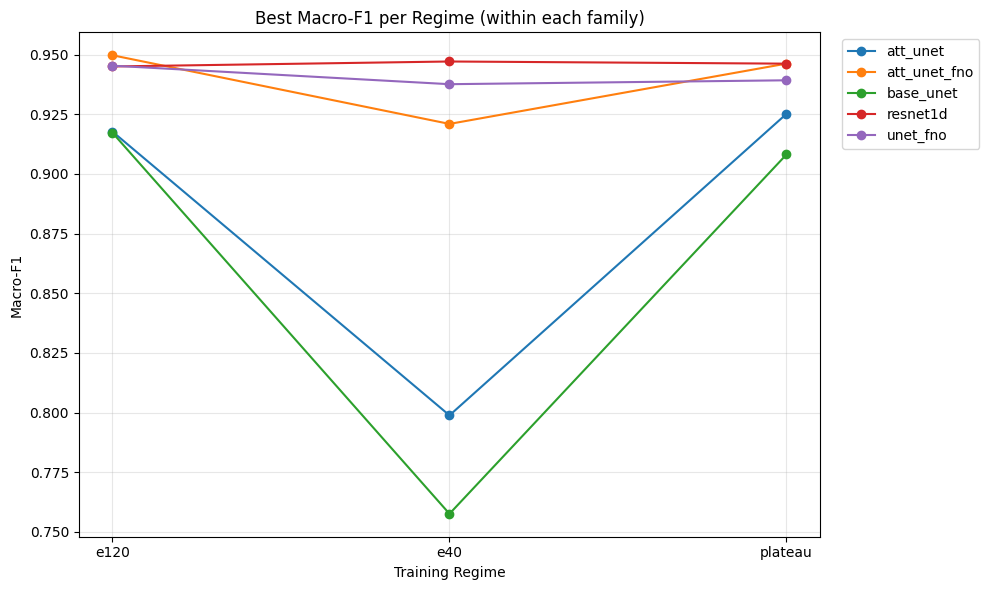

In [ ]:
# ===========================================================
# Compare regimes within each family (using best per regime)
#   Table + quick plot (macro-F1)
# ===========================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

MODELS_DIR = Path("models") / DATASET_NAME
BEST_REGIME_PATH = MODELS_DIR / "eval_best_per_family_per_regime.csv"

df_best_regime = pd.read_csv(BEST_REGIME_PATH)

# Pivot table: rows=family, cols=regime, values=macro_f1
pivot = df_best_regime.pivot_table(
    index="family",
    columns="train_regime",
    values="macro_f1",
    aggfunc="max"
).sort_index()

display(pivot)

# Plot: one subplot per family (clean + readable)
families = list(pivot.index)
n = len(families)
fig_h = max(4, 1.2 * n)

plt.figure(figsize=(10, fig_h))
for i, fam in enumerate(families):
    vals = pivot.loc[fam].dropna()
    xs = list(vals.index)
    ys = list(vals.values)
    plt.plot(xs, ys, marker="o", label=fam)

plt.title("Best Macro-F1 per Regime (within each family)")
plt.ylabel("Macro-F1")
plt.xlabel("Training Regime")
plt.grid(alpha=0.3)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [ ]:
# ===========================================================
# Best overall per family (best regime picked per family)
#   -> models/<DATASET_NAME>/eval_best_overall_per_family.csv
# ===========================================================

import pandas as pd
from pathlib import Path

MODELS_DIR = Path("models") / DATASET_NAME
BEST_REGIME_PATH = MODELS_DIR / "eval_best_per_family_per_regime.csv"
OUT_PATH = MODELS_DIR / "eval_best_overall_per_family.csv"

df_best_regime = pd.read_csv(BEST_REGIME_PATH)

best_overall = (
    df_best_regime.sort_values("macro_f1", ascending=False)
                  .groupby("family", as_index=False)
                  .head(1)
                  .reset_index(drop=True)
)

best_overall.to_csv(OUT_PATH, index=False)
print("Saved:", OUT_PATH)

best_overall


Saved: models\NonInvasiveFetalECGThorax1\eval_best_overall_per_family.csv


,family,train_regime,run_dir,run_id,base,lr,weight_decay,dropout,test_acc,macro_f1,balanced_acc,params_million,val_acc,epochs_ran,test_loss,best_epoch,best_val_acc,best_val_loss,modes,fno_layers
0,att_unet_fno,e120,models/NonInvasiveFetalECGThorax1/att_unet_fno...,run_198,48,0.0005,0.0000,0.2,0.951654,0.949749,0.949799,2.225640,0.947222,120,0.178586,NaN,NaN,NaN,24.0,2.0
1,resnet1d,e40,models/NonInvasiveFetalECGThorax1/resnet1d/e40...,run_035,48,0.0005,0.0001,0.1,0.950127,0.947138,0.948294,2.180250,0.938889,40,0.160367,NaN,NaN,NaN,NaN,NaN
2,unet_fno,e120,models/NonInvasiveFetalECGThorax1/unet_fno/e12...,run_171,48,0.0010,0.0001,0.1,0.948092,0.945381,0.945826,0.996522,0.938889,120,0.185795,NaN,NaN,NaN,16.0,1.0
3,att_unet,plateau,models/NonInvasiveFetalECGThorax1/att_unet/pla...,run_028,48,0.0010,0.0001,0.0,0.928244,0.925197,0.926520,0.381288,0.930556,151,0.274430,131.0,0.930556,0.292017,NaN,NaN
4,base_unet,e120,models/NonInvasiveFetalECGThorax1/base_unet/e1...,run_028,48,0.0010,0.0001,0.0,0.921120,0.917273,0.918554,0.369258,0.908333,120,0.317170,NaN,NaN,NaN,NaN,NaN


In [ ]:
# ===========================================================
# Param-matched best models (ALL runs, cross-family)
# Adds reference metrics in each row for direct comparison
#
# Output:
#   models/<DATASET_NAME>/param_matched_cross_family.csv
# ===========================================================

import pandas as pd
from pathlib import Path
import numpy as np

MODELS_DIR = Path("models") / DATASET_NAME
ALL_PATH = MODELS_DIR / "eval_stats_all.csv"
OUT_PATH = MODELS_DIR / "param_matched_cross_family.csv"

TOL = 0.10  # ±10%

df = pd.read_csv(ALL_PATH)

required = {"family", "macro_f1", "balanced_acc", "test_acc", "params_million", "train_regime", "run_dir"}
missing = required - set(df.columns)
if missing:
    raise RuntimeError(f"eval_stats_all.csv missing required columns: {missing}")

# Clean + ensure numeric
df = df.copy()
df["family"] = df["family"].astype(str).str.strip()
df["train_regime"] = df["train_regime"].astype(str).str.strip()
df["params_million"] = pd.to_numeric(df["params_million"], errors="coerce")
df["macro_f1"] = pd.to_numeric(df["macro_f1"], errors="coerce")
df["balanced_acc"] = pd.to_numeric(df["balanced_acc"], errors="coerce")
df["test_acc"] = pd.to_numeric(df["test_acc"], errors="coerce")

df = df.dropna(subset=["params_million", "macro_f1", "balanced_acc"])

families = sorted(df["family"].unique().tolist())

# Best run overall per family (reference points)
best_overall = (
    df.sort_values("macro_f1", ascending=False)
      .groupby("family", as_index=False)
      .head(1)
      .reset_index(drop=True)
)

rows = []

for _, ref in best_overall.iterrows():
    ref_family = ref["family"]
    ref_params = float(ref["params_million"])
    lo, hi = ref_params * (1 - TOL), ref_params * (1 + TOL)

    ref_pack = {
        "reference_family": ref_family,
        "ref_params_million": ref_params,
        "ref_macro_f1": float(ref["macro_f1"]),
        "ref_balanced_acc": float(ref["balanced_acc"]),
        "ref_test_acc": float(ref["test_acc"]) if "test_acc" in ref else np.nan,
        "ref_train_regime": ref.get("train_regime", "unknown"),
        "ref_run_dir": ref.get("run_dir", ""),
    }

    # Reference row (self)
    rows.append({
        **ref_pack,
        "target_family": ref_family,
        "matched": True,
        "target_params_million": ref_params,
        "param_ratio": 1.0,
        "macro_f1": float(ref["macro_f1"]),
        "balanced_acc": float(ref["balanced_acc"]),
        "test_acc": float(ref["test_acc"]) if "test_acc" in ref else np.nan,
        "train_regime": ref.get("train_regime", "unknown"),
        "run_dir": ref.get("run_dir", ""),
    })

    # Match other families
    for fam in families:
        if fam == ref_family:
            continue

        sub = df[df["family"] == fam]
        sub = sub[(sub["params_million"] >= lo) & (sub["params_million"] <= hi)]

        if sub.empty:
            rows.append({
                **ref_pack,
                "target_family": fam,
                "matched": False,
                "target_params_million": np.nan,
                "param_ratio": np.nan,
                "macro_f1": np.nan,
                "balanced_acc": np.nan,
                "test_acc": np.nan,
                "train_regime": "",
                "run_dir": "",
            })
            continue

        best_match = sub.sort_values("macro_f1", ascending=False).iloc[0]
        tparams = float(best_match["params_million"])

        rows.append({
            **ref_pack,
            "target_family": fam,
            "matched": True,
            "target_params_million": tparams,
            "param_ratio": tparams / ref_params if ref_params > 0 else np.nan,
            "macro_f1": float(best_match["macro_f1"]),
            "balanced_acc": float(best_match["balanced_acc"]),
            "test_acc": float(best_match["test_acc"]) if "test_acc" in best_match else np.nan,
            "train_regime": best_match.get("train_regime", "unknown"),
            "run_dir": best_match.get("run_dir", ""),
        })

out = pd.DataFrame(rows)

# Useful delta columns (optional, but helps reading)
out["delta_macro_f1"] = out["macro_f1"] - out["ref_macro_f1"]
out["delta_balanced_acc"] = out["balanced_acc"] - out["ref_balanced_acc"]

out = out.sort_values(
    ["reference_family", "matched", "macro_f1"],
    ascending=[True, False, False]
).reset_index(drop=True)

out.to_csv(OUT_PATH, index=False)
print("Saved:", OUT_PATH)

cols_show = [
    "reference_family", "target_family", "matched",
    "ref_params_million", "target_params_million", "param_ratio",
    "ref_macro_f1", "macro_f1", "delta_macro_f1",
    "ref_balanced_acc", "balanced_acc", "delta_balanced_acc",
    "ref_train_regime", "train_regime",
]
out[cols_show]


Saved: models\NonInvasiveFetalECGThorax1\param_matched_cross_family.csv


,reference_family,target_family,matched,ref_params_million,target_params_million,param_ratio,ref_macro_f1,macro_f1,delta_macro_f1,ref_balanced_acc,balanced_acc,delta_balanced_acc,ref_train_regime,train_regime
0,att_unet,att_unet,True,0.381288,0.381288,1.000000,0.925197,0.925197,0.000000,0.926520,0.926520,0.000000,plateau,plateau
1,att_unet,base_unet,True,0.381288,0.369258,0.968449,0.925197,0.917273,-0.007924,0.926520,0.918554,-0.007966,plateau,e120
2,att_unet,att_unet_fno,False,0.381288,NaN,NaN,0.925197,NaN,NaN,0.926520,NaN,NaN,plateau,
3,att_unet,resnet1d,False,0.381288,NaN,NaN,0.925197,NaN,NaN,0.926520,NaN,NaN,plateau,
4,att_unet,unet_fno,False,0.381288,NaN,NaN,0.925197,NaN,NaN,0.926520,NaN,NaN,plateau,
5,att_unet_fno,att_unet_fno,True,2.225640,2.225640,1.000000,0.949749,0.949749,0.000000,0.949799,0.949799,0.000000,e120,e120
6,att_unet_fno,resnet1d,True,2.225640,2.180250,0.979606,0.949749,0.947138,-0.002611,0.949799,0.948294,-0.001506,e120,e40
7,att_unet_fno,unet_fno,True,2.225640,2.213610,0.994595,0.949749,0.942725,-0.007024,0.949799,0.944571,-0.005228,e120,e120
8,att_unet_fno,att_unet,False,2.225640,NaN,NaN,0.949749,NaN,NaN,0.949799,NaN,NaN,e120,
9,att_unet_fno,base_unet,False,2.225640,NaN,NaN,0.949749,NaN,NaN,0.949799,NaN,NaN,e120,


### Plots for evaluation

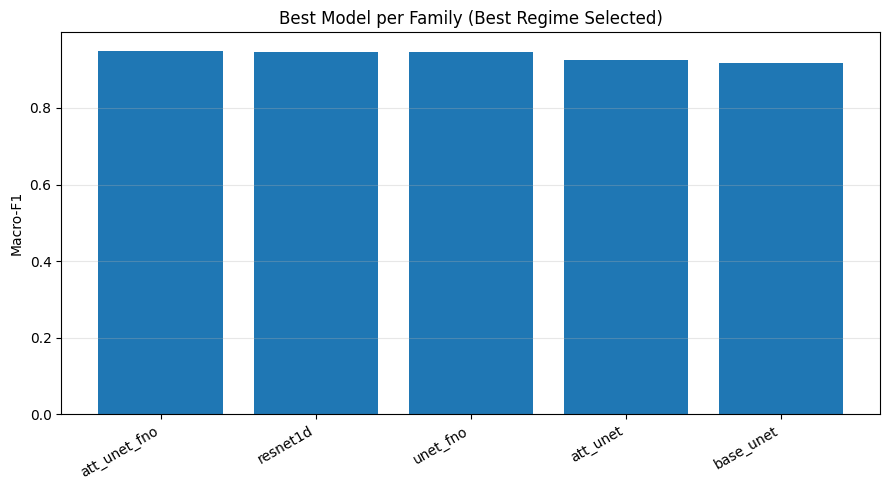

,family,train_regime,macro_f1,balanced_acc,test_acc,params_million,run_dir
0,att_unet_fno,e120,0.949749,0.949799,0.951654,2.225640,models/NonInvasiveFetalECGThorax1/att_unet_fno...
1,resnet1d,e40,0.947138,0.948294,0.950127,2.180250,models/NonInvasiveFetalECGThorax1/resnet1d/e40...
2,unet_fno,e120,0.945381,0.945826,0.948092,0.996522,models/NonInvasiveFetalECGThorax1/unet_fno/e12...
3,att_unet,plateau,0.925197,0.926520,0.928244,0.381288,models/NonInvasiveFetalECGThorax1/att_unet/pla...
4,base_unet,e120,0.917273,0.918554,0.921120,0.369258,models/NonInvasiveFetalECGThorax1/base_unet/e1...


In [ ]:
# ===========================================================
# Plot: Best overall Macro-F1 per family (best regime chosen)
# ===========================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

MODELS_DIR = Path("models") / DATASET_NAME
BEST_OVERALL_PATH = MODELS_DIR / "eval_best_overall_per_family.csv"

df = pd.read_csv(BEST_OVERALL_PATH).sort_values("macro_f1", ascending=False)

plt.figure(figsize=(9,5))
plt.bar(df["family"], df["macro_f1"])
plt.ylabel("Macro-F1")
plt.title("Best Model per Family (Best Regime Selected)")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

df[["family","train_regime","macro_f1","balanced_acc","test_acc","params_million","run_dir"]]


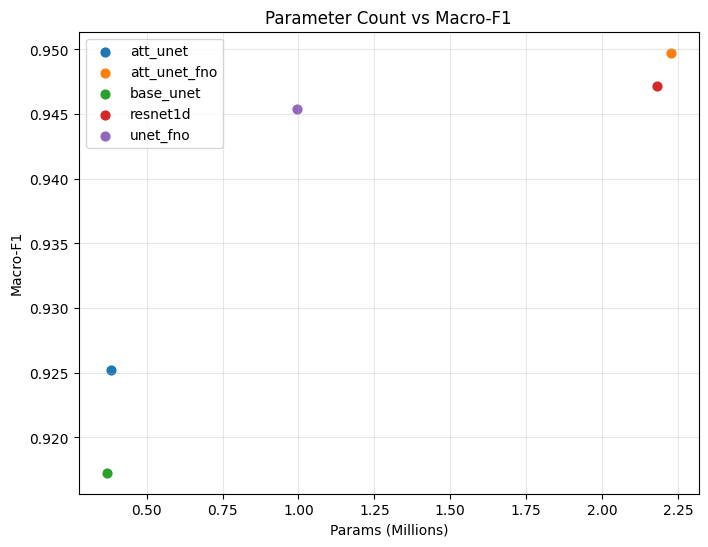

In [ ]:
# Params vs Macro-F1

plt.figure(figsize=(8,6))

for fam in families:
    sub = df[df["family"] == fam]
    plt.scatter(sub["params_million"], sub["macro_f1"], label=fam, s=40)

plt.xlabel("Params (Millions)")
plt.ylabel("Macro-F1")
plt.title("Parameter Count vs Macro-F1")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


<Figure size 1000x600 with 0 Axes>

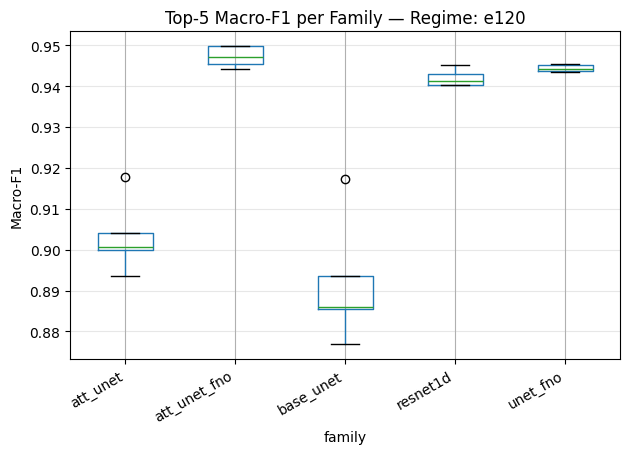

<Figure size 1000x600 with 0 Axes>

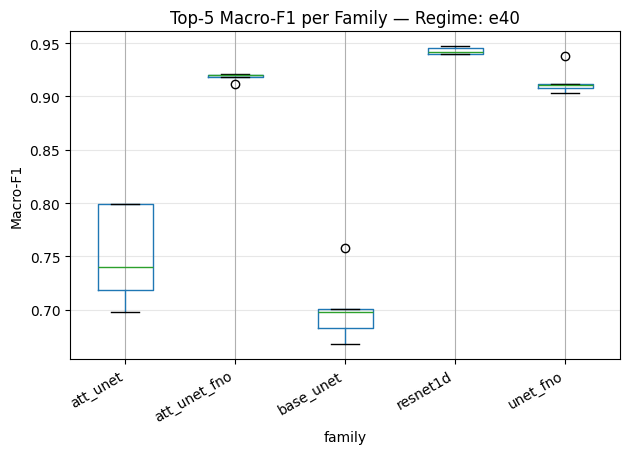

<Figure size 1000x600 with 0 Axes>

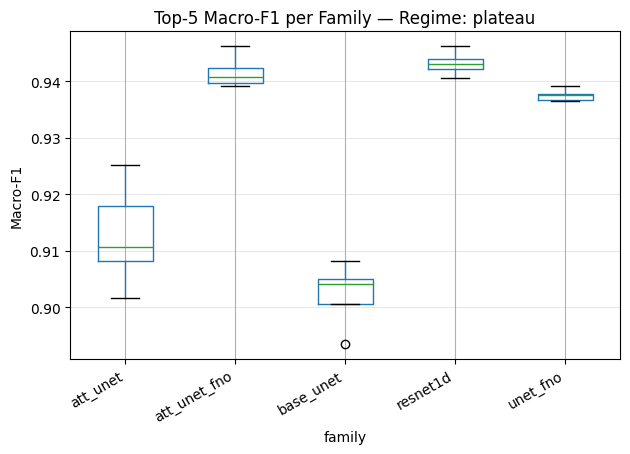

In [ ]:
# ===========================================================
# Boxplots: Top-k Macro-F1 per family, per regime
#   Uses: top5_per_family_per_regime.csv
# ===========================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

MODELS_DIR = Path("models") / DATASET_NAME
TOP5_REGIME_PATH = MODELS_DIR / "top5_per_family_per_regime.csv"

df = pd.read_csv(TOP5_REGIME_PATH)

for regime in sorted(df["train_regime"].unique()):
    sub = df[df["train_regime"] == regime]

    plt.figure(figsize=(10,6))
    sub.boxplot(column="macro_f1", by="family")
    plt.title(f"Top-5 Macro-F1 per Family — Regime: {regime}")
    plt.suptitle("")
    plt.ylabel("Macro-F1")
    plt.xticks(rotation=30, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


In [ ]:
# ===========================================================
# Export evaluation figures to JPGs into figs/<DATASET_NAME>/
#   Selection: BEST per family overall (from eval_stats_all.csv)
#   No dependence on top5 CSV files.
#
# Outputs:
#   confusion_<family>.jpg                  (one per family, high-res, annotated)
#   per_class_f1.jpg OR per_class_f1_partXX.jpg
#   top5_boxplot_overall.jpg
#   top5_boxplot_per_regime__<regime>.jpg
#   params_vs_macroF1.jpg
#   regime_wins_per_family.jpg
#   best_macroF1_heatmap_family_by_regime.jpg
# ===========================================================

import json
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, confusion_matrix

# ---------- Paths ----------
MODELS_DIR = Path("models") / DATASET_NAME
EVAL_ALL_PATH = MODELS_DIR / "eval_stats_all.csv"
FIG_DIR = Path("figs") / DATASET_NAME
FIG_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Families expected (we will filter to those that exist)
families_order = ["base_unet", "unet_fno", "att_unet", "att_unet_fno", "resnet1d"]
pretty_names = {
    "base_unet":     "U-Net",
    "unet_fno":      "U-Net + FNO",
    "att_unet":      "Attention U-Net",
    "att_unet_fno":  "Attention U-Net + FNO",
    "resnet1d":      "ResNet1D",
}

# ---------- Load eval table ----------
if not EVAL_ALL_PATH.exists():
    raise FileNotFoundError(f"Missing: {EVAL_ALL_PATH}. Run evaluation first.")

df_all = pd.read_csv(EVAL_ALL_PATH)

# basic cleanup
df_all["family"] = df_all["family"].astype(str).str.strip()
df_all["train_regime"] = df_all["train_regime"].astype(str).str.strip()
df_all["macro_f1"] = pd.to_numeric(df_all["macro_f1"], errors="coerce")
df_all["params_million"] = pd.to_numeric(df_all.get("params_million", np.nan), errors="coerce")

df_all = df_all.dropna(subset=["macro_f1"])

fams_available = [f for f in families_order if (df_all["family"] == f).any()]
if not fams_available:
    fams_available = sorted(df_all["family"].unique().tolist())

print("Families for plotting:", fams_available)
print("Regimes seen:", sorted(df_all["train_regime"].dropna().unique().tolist()))


# ---------- Helpers ----------
def load_model_from_run_dir(family: str, run_dir: str):
    run_dir = Path(str(run_dir))
    cfg_path = run_dir / "config.json"
    w_path = run_dir / "model.pt"

    with open(cfg_path, "r") as f:
        cfg = json.load(f)

    model = build_model(family, cfg)
    state = torch.load(w_path, map_location=device)
    model.load_state_dict(state)
    model.to(device).eval()
    return model, cfg

@torch.no_grad()
def predict_all(model, loader):
    y_true_all, y_pred_all = [], []
    for xb, yb in loader:
        xb = xb.to(device)
        logits = model(xb)
        preds = logits.argmax(1).cpu().numpy()
        y_pred_all.append(preds)
        y_true_all.append(yb.numpy())
    y_true = np.concatenate(y_true_all)
    y_pred = np.concatenate(y_pred_all)
    return y_true, y_pred


# ===========================================================
# Selection: BEST per family overall (by macro_f1)
# ===========================================================
df_best_overall = (
    df_all.sort_values("macro_f1", ascending=False)
          .groupby("family", as_index=False)
          .head(1)
          .reset_index(drop=True)
)

# keep in our preferred order
df_best_overall["family"] = pd.Categorical(df_best_overall["family"], fams_available, ordered=True)
df_best_overall = df_best_overall.sort_values("family")

display(df_best_overall[["family","train_regime","macro_f1","balanced_acc","test_acc","params_million","run_dir"]]
        if "balanced_acc" in df_best_overall.columns else df_best_overall[["family","train_regime","macro_f1","test_acc","params_million","run_dir"]])


# ===========================================================
# 1) Confusion matrices (one per family, high-res, annotated)
# ===========================================================
print("Exporting confusion matrices...")

K = len(classes)

for _, row in df_best_overall.iterrows():
    fam = str(row["family"])
    run_dir = row["run_dir"]

    model, _ = load_model_from_run_dir(fam, run_dir)
    y_true, y_pred = predict_all(model, test_loader)

    label_ids = np.arange(K)
    cm = confusion_matrix(y_true, y_pred, labels=label_ids)

    # ---- sizing: scale with K ----
    side = max(10.0, min(34.0, 0.70 * K))
    fig, ax = plt.subplots(figsize=(side, side))
    im = ax.imshow(cm, cmap="Blues", interpolation="nearest")

    # ticks/fonts
    tick_fs = 12 if K <= 10 else 10 if K <= 20 else 8 if K <= 40 else 6
    ax.set_xticks(np.arange(K))
    ax.set_yticks(np.arange(K))
    ax.set_xticklabels(classes, rotation=45, ha="right", fontsize=tick_fs)
    ax.set_yticklabels(classes, fontsize=tick_fs)

    ax.set_xlabel("Predicted", fontsize=14, labelpad=10)
    ax.set_ylabel("True", fontsize=14, labelpad=10)

    title = f"{pretty_names.get(fam,fam)} — Confusion Matrix\nmacro-F1={row['macro_f1']:.3f} | regime={row.get('train_regime','?')}"
    ax.set_title(title, fontsize=16, pad=18)

    # minor gridlines
    ax.set_xticks(np.arange(-.5, K, 1), minor=True)
    ax.set_yticks(np.arange(-.5, K, 1), minor=True)
    ax.grid(which="minor", linestyle="-", linewidth=0.35, alpha=0.25)
    ax.tick_params(which="minor", bottom=False, left=False)

    # ---- annotate EVERY cell (you requested this) ----
    # font size for numbers scales down with K
    cell_fs = 10 if K <= 10 else 8 if K <= 20 else 6 if K <= 40 else 4
    thresh = cm.max() * 0.6 if cm.max() > 0 else 0.0

    for (r, c), val in np.ndenumerate(cm):
        ax.text(
            c, r, str(int(val)),
            ha="center", va="center",
            fontsize=cell_fs,
            color="white" if val > thresh else "black"
        )

    # colorbar
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
    cbar.ax.set_ylabel("Count", rotation=90, fontsize=14)
    cbar.ax.tick_params(labelsize=12)

    plt.tight_layout()
    plt.savefig(FIG_DIR / f"confusion_{fam}.jpg", dpi=450, bbox_inches="tight")
    plt.close(fig)

print("✅ Confusion matrices exported.")


# ===========================================================
# 2) Per-class F1 comparison (single if K<=9 else chunked)
# ===========================================================
print("Exporting per-class F1 plots...")

def per_class_f1(model):
    y_true, y_pred = predict_all(model, test_loader)
    label_ids = np.arange(K)
    return f1_score(y_true, y_pred, labels=label_ids, average=None, zero_division=0)

per_class = {}
for _, row in df_best_overall.iterrows():
    fam = str(row["family"])
    model, _ = load_model_from_run_dir(fam, row["run_dir"])
    per_class[fam] = per_class_f1(model)

# Plot logic
if K <= 9:
    x = np.arange(K)
    width = 0.8 / max(len(per_class), 1)

    fig, ax = plt.subplots(figsize=(11, 6))
    for i, fam in enumerate(per_class.keys()):
        ax.bar(x + i * width, per_class[fam], width, label=pretty_names.get(fam, fam), alpha=0.85)

    ax.set_xticks(x + width * (len(per_class) - 1) / 2)
    ax.set_xticklabels(classes, rotation=45, ha="right")
    ax.set_ylabel("F1 Score")
    ax.set_title("Per-Class F1 Comparison (Best Overall per Family)")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.savefig(FIG_DIR / "per_class_f1.jpg", dpi=350, bbox_inches="tight")
    plt.close(fig)
else:
    chunk = 5
    width = 0.8 / max(len(per_class), 1)

    part = 1
    for start in range(0, K, chunk):
        end = min(start + chunk, K)
        idx = np.arange(start, end)

        fig, ax = plt.subplots(figsize=(10, 5))
        for i, fam in enumerate(per_class.keys()):
            ax.bar(
                np.arange(len(idx)) + i * width,
                per_class[fam][start:end],
                width=width,
                label=pretty_names.get(fam, fam),
                alpha=0.85
            )

        ax.set_xticks(np.arange(len(idx)) + width * (len(per_class) - 1) / 2)
        ax.set_xticklabels(classes[start:end], rotation=45, ha="right")
        ax.set_ylabel("F1 Score")
        ax.set_title(f"Per-Class F1 (classes {start+1}–{end}) — Best Overall per Family")
        ax.grid(axis="y", alpha=0.3)
        ax.legend()

        plt.tight_layout()
        plt.savefig(FIG_DIR / f"per_class_f1_part{part:02d}.jpg", dpi=350, bbox_inches="tight")
        plt.close(fig)
        part += 1

print("✅ Per-class F1 plot(s) exported.")


# ===========================================================
# 3) Top-5 boxplots (computed from eval_stats_all.csv)
#   A) Top-5 per family overall
#   B) Top-5 per family per regime (one figure per regime)
# ===========================================================
print("Exporting top-5 boxplots...")

# A) overall top-5 per family (regimes mixed, but top-5 selected overall)
top5_overall = (
    df_all.sort_values("macro_f1", ascending=False)
          .groupby("family", as_index=False)
          .head(5)
          .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(10, 6))
top5_overall.boxplot(column="macro_f1", by="family", ax=ax)
ax.set_title("Top-5 Macro-F1 per Family (Overall)")
ax.set_ylabel("Macro-F1")
plt.suptitle("")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "top5_boxplot_overall.jpg", dpi=350, bbox_inches="tight")
plt.close(fig)

# B) top-5 per family per regime
regimes = sorted(df_all["train_regime"].dropna().unique().tolist())
for reg in regimes:
    sub = df_all[df_all["train_regime"] == reg]
    if sub.empty:
        continue

    top5_reg = (
        sub.sort_values("macro_f1", ascending=False)
           .groupby("family", as_index=False)
           .head(5)
           .reset_index(drop=True)
    )

    fig, ax = plt.subplots(figsize=(10, 6))
    top5_reg.boxplot(column="macro_f1", by="family", ax=ax)
    ax.set_title(f"Top-5 Macro-F1 per Family — Regime: {reg}")
    ax.set_ylabel("Macro-F1")
    plt.suptitle("")
    plt.xticks(rotation=30, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"top5_boxplot_per_regime__{reg}.jpg", dpi=350, bbox_inches="tight")
    plt.close(fig)

print("✅ Boxplots exported.")


# ===========================================================
# 4) Params vs Macro-F1 scatter (ALL runs)
# ===========================================================
print("Exporting params_vs_macroF1.jpg ...")

fig, ax = plt.subplots(figsize=(9, 6))

for fam in fams_available:
    sub = df_all[df_all["family"] == fam].dropna(subset=["params_million", "macro_f1"])
    if sub.empty:
        continue
    ax.scatter(
        sub["params_million"],
        sub["macro_f1"],
        label=pretty_names.get(fam, fam),
        alpha=0.65
    )

ax.set_xlabel("Params (Millions)")
ax.set_ylabel("Macro-F1")
ax.set_title("Parameter Count vs Macro-F1 (All Runs)")
ax.grid(alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "params_vs_macroF1.jpg", dpi=350, bbox_inches="tight")
plt.close(fig)

print("✅ Params vs Macro-F1 exported.")


# ===========================================================
# 5) Regime visualization (which regime wins?)
#   A) regime_wins_per_family.jpg (bar chart counts)
#   B) best_macroF1_heatmap_family_by_regime.jpg (heatmap of best macroF1)
# ===========================================================
print("Exporting regime comparison visuals...")

# A) Winning regime per family (based on best macro_f1 within that family/regime)
best_per_fam_reg = (
    df_all.sort_values("macro_f1", ascending=False)
          .groupby(["family", "train_regime"], as_index=False)
          .head(1)
          .reset_index(drop=True)
)

# pick winner regime for each family
winner = (
    best_per_fam_reg.sort_values("macro_f1", ascending=False)
                    .groupby("family", as_index=False)
                    .head(1)
                    .reset_index(drop=True)
)

# count wins
win_counts = winner["train_regime"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(win_counts.index.astype(str), win_counts.values)
ax.set_title("Which Training Regime Wins per Family? (by Macro-F1)")
ax.set_xlabel("Regime")
ax.set_ylabel("#Families where regime is best")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "regime_wins_per_family.jpg", dpi=350, bbox_inches="tight")
plt.close(fig)

# B) Heatmap: best macro-F1 per family × regime
pivot = best_per_fam_reg.pivot_table(
    index="family", columns="train_regime", values="macro_f1", aggfunc="max"
)
pivot = pivot.reindex(index=fams_available)

fig, ax = plt.subplots(figsize=(10, max(4, 0.6 * len(pivot))))
im = ax.imshow(pivot.values, cmap="Blues", aspect="auto")

ax.set_xticks(np.arange(pivot.shape[1]))
ax.set_xticklabels(pivot.columns.astype(str), rotation=30, ha="right")
ax.set_yticks(np.arange(pivot.shape[0]))
ax.set_yticklabels([pretty_names.get(f, f) for f in pivot.index])

# annotate heatmap cells
for r in range(pivot.shape[0]):
    for c in range(pivot.shape[1]):
        val = pivot.values[r, c]
        if np.isnan(val):
            txt = "-"
        else:
            txt = f"{val:.3f}"
        ax.text(c, r, txt, ha="center", va="center", fontsize=10)

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
cbar.ax.set_ylabel("Macro-F1", rotation=90)

ax.set_title("Best Macro-F1 per Family by Training Regime")
plt.tight_layout()
plt.savefig(FIG_DIR / "best_macroF1_heatmap_family_by_regime.jpg", dpi=350, bbox_inches="tight")
plt.close(fig)

print(f"✅ All plot exports completed: {FIG_DIR.resolve()}")


Using device: cuda
Families for plotting: ['base_unet', 'unet_fno', 'att_unet', 'att_unet_fno', 'resnet1d']
Regimes seen: ['e120', 'e40', 'plateau']


,family,train_regime,macro_f1,balanced_acc,test_acc,params_million,run_dir
4,base_unet,e120,0.917273,0.918554,0.921120,0.369258,models/NonInvasiveFetalECGThorax1/base_unet/e1...
2,unet_fno,e120,0.945381,0.945826,0.948092,0.996522,models/NonInvasiveFetalECGThorax1/unet_fno/e12...
3,att_unet,plateau,0.925197,0.926520,0.928244,0.381288,models/NonInvasiveFetalECGThorax1/att_unet/pla...
0,att_unet_fno,e120,0.949749,0.949799,0.951654,2.225640,models/NonInvasiveFetalECGThorax1/att_unet_fno...
1,resnet1d,e40,0.947138,0.948294,0.950127,2.180250,models/NonInvasiveFetalECGThorax1/resnet1d/e40...


Exporting confusion matrices...


C:\Users\Hontika\AppData\Local\Temp\ipykernel_58464\1569693218.py:75: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state = torch.load(w_path, map_location=device)
C:\Users\

✅ Confusion matrices exported.
Exporting per-class F1 plots...


C:\Users\Hontika\AppData\Local\Temp\ipykernel_58464\1569693218.py:75: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state = torch.load(w_path, map_location=device)
C:\Users\

✅ Per-class F1 plot(s) exported.
Exporting top-5 boxplots...
✅ Boxplots exported.
Exporting params_vs_macroF1.jpg ...
✅ Params vs Macro-F1 exported.
Exporting regime comparison visuals...
✅ All plot exports completed: E:\Repos\U-net_cikk\figs\NonInvasiveFetalECGThorax1


In [ ]:
import pandas as pd
from pathlib import Path

MODELS_DIR = Path("models") / DATASET_NAME
eval_stats_path = MODELS_DIR / "eval_stats.csv"

df = pd.read_csv(eval_stats_path)

families = ["base_unet", "unet_fno", "att_unet", "att_unet_fno", "resnet1d"]
pretty = {
    "base_unet":    "U-Net",
    "unet_fno":     "U-Net + FNO",
    "att_unet":     "Attention U-Net",
    "att_unet_fno": "Attention U-Net + FNO",
    "resnet1d":     "ResNet1D",
}

print("% LaTeX rows for Table: Best configuration per model family")
for fam in families:
    sub = df[df["family"] == fam]
    if sub.empty:
        continue
    best = sub.sort_values("macro_f1", ascending=False).iloc[0]

    family_name = pretty[fam]
    macro  = best["macro_f1"]
    bal    = best["balanced_acc"]
    acc    = best["test_acc"]
    params = best.get("params_million", float("nan"))
    run_id = best["run_id"]
    base   = best["base"]

    row = (
        f"{family_name:23} & "
        f"{macro:.3f} & {bal:.3f} & {acc:.3f} & "
        f"{params:.2f} & \\texttt{{{run_id}}} & {int(base)} \\\\"
    )
    print(row)


FileNotFoundError: [Errno 2] No such file or directory: 'models\\NonInvasiveFetalECGThorax1\\eval_stats.csv'

In [ ]:
!python -m nbconvert --to script Pipeline.ipynb


[NbConvertApp] Converting notebook Pipeline.ipynb to script
[NbConvertApp] Writing 73667 bytes to Pipeline.py
